# Avaliação

Neste notebook avalio em detalhe o modelo escolhido no notebook 03: **SVM + `e5_large`** (kernel RBF, `C=10`, `class_weight='balanced'`, sem `StandardScaler`).

A avaliação analisa:
- Matriz de confusão
- Precision
- Recall
- Especificidade
- F1
- Confusão entre classes parecidas
- Curva de aprendizado
- Projeção dos embeddings com PCA

Para ter referência, comparo o modelo com mais dois:

- **Regressão Logística + `e5_large`:** segundo melhor na validação cruzada.
- **SVM + TF-IDF:** melhor modelo com TF-IDF.

### 0. Imports e carregamento

In [134]:
import pandas as pd
import numpy as np
import joblib
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
RANDOM_STATE = 42

#### Dataset e divisão treino/teste
Mesma divisão do notebook 03, sem precisar rodá-lo, usando os índices das frases do treino e do teste (`idx_train` e `idx_test`), gerados pelo arquivo de embeddings `e5_large.npz`.

In [135]:
df = pd.read_csv('../data/processed/df_02.csv')

emb = np.load('../data/embeddings/e5_large.npz')
idx_train, idx_test = emb['idx_train'], emb['idx_test']
emb_train, emb_test = emb['train'], emb['test']

# as linhas dos embeddings seguem a ordem de idx_train e idx_test
X_train, X_test = df.loc[idx_train, 'frase'], df.loc[idx_test, 'frase']
y_train, y_test = df.loc[idx_train, 'rotulo'], df.loc[idx_test, 'rotulo']

# mesma divisão do notebook 03 (80/20, estratificada pelo rótulo)
_, X_test_03 = train_test_split(df['frase'], test_size=0.2, stratify=df['rotulo'], random_state=RANDOM_STATE)

print(f'Treino: {len(X_train)} frases | Teste: {len(X_test)} frases | Rótulos: {y_test.nunique()}')

Treino: 10024 frases | Teste: 2506 frases | Rótulos: 77


#### Modelos
Carrego as buscas salvas em `data/buscas/`. Como as buscas usaram `refit`, o `GridSearchCV` já treinou o melhor modelo de cada uma no treino inteiro, então não é preciso realizar mais nenhum treino

In [136]:
PASTA_BUSCAS = Path('../data/buscas')

# Carrega a busca e confere se ela foi treinada com a mesma divisão
def carregar_busca(nome):
    salvo = joblib.load(PASTA_BUSCAS / f'{nome}.joblib')
    assert np.array_equal(salvo['idx_train'], idx_train), f'{nome}: divisão diferente'
    return salvo['busca']

# {nome do modelo: (busca, X do treino, X do teste)}
MODELOS = {
    'SVM + e5_large': (carregar_busca('svc_e5_large'), emb_train, emb_test),
    'Regressão Logística + e5_large': (carregar_busca('reglog_e5_large_c'), emb_train, emb_test),
    'SVM + TF-IDF': (carregar_busca('svc_tfidf'), X_train, X_test),
}
PRINCIPAL = 'SVM + e5_large'

for nome, (busca, _, _) in MODELOS.items():
    print(f'{nome}: F1-macro (CV) = {busca.best_score_:.4f}')
    print('   ', busca.best_params_)

SVM + e5_large: F1-macro (CV) = 0.9286
    {'clf__C': 10, 'clf__class_weight': 'balanced', 'clf__gamma': 'scale', 'clf__kernel': 'rbf', 'scaler': 'passthrough'}
Regressão Logística + e5_large: F1-macro (CV) = 0.9237
    {'clf__C': 150, 'clf__class_weight': 'balanced', 'scaler': 'passthrough'}
SVM + TF-IDF: F1-macro (CV) = 0.8830
    {'clf__C': 1, 'clf__class_weight': 'balanced', 'clf__coef0': 1, 'clf__degree': 2, 'clf__gamma': 1, 'clf__kernel': 'poly', 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1), 'tfidf__stop_words': None, 'tfidf__sublinear_tf': True}


In [137]:
# Classe prevista por cada modelo no teste
y_pred = {nome: busca.predict(X_te) for nome, (busca, _, X_te) in MODELOS.items()}

modelo_principal = MODELOS[PRINCIPAL][0]
CLASSES = modelo_principal.classes_  # ordem alfabética
previsto = y_pred[PRINCIPAL]

### 1. Métricas gerais

Com 77 classes, cada métrica é calculada **para cada classe**, tratando ela como a positiva e todas as outras como negativas (um contra todos). Para a classe $k$:

- $VP_k$: frases da classe $k$ previstas como $k$;
- $FP_k$: frases de outras classes previstas como $k$;
- $FN_k$: frases da classe $k$ previstas como outra classe;
- $VN_k$: frases de outras classes que não foram previstas como $k$.

$$\text{Precision}_k = \frac{VP_k}{VP_k + FP_k} \qquad \text{Recall}_k = \frac{VP_k}{VP_k + FN_k} \qquad F1_k = 2 \times \frac{\text{Precision}_k \times \text{Recall}_k}{\text{Precision}_k + \text{Recall}_k}$$

Resumo de cada métrica:

- **Precision:** das frases que o modelo previu como classe $k$, quantas realmente são dela. Responde: *"quando o modelo diz que é $k$, posso confiar?"*
- **Recall:** das frases que realmente são da classe $k$, quantas o modelo encontrou. Responde: *"de tudo que era $k$, quanto o modelo capturou?"*
- **F1:** média harmônica entre precision e recall. Só fica alto quando as duas são altas, pois penaliza quando uma delas é baixa.

Depois, os 77 valores são resumidos em um só número, de duas formas:

- **Média macro:** média simples das classes, todas com o mesmo peso. Métrica principal do projeto (F1-macro).
- **Média weighted:** média ponderada pelo número de frases de cada classe no teste. Com isso, classes maiores pesam mais.

In [138]:
def metricas(y_true, y_prev):
    return {
        'acurácia': accuracy_score(y_true, y_prev),
        'precision_macro': precision_score(y_true, y_prev, average='macro'),
        'recall_macro': recall_score(y_true, y_prev, average='macro'),
        'f1_macro': f1_score(y_true, y_prev, average='macro'),
        'precision_weighted': precision_score(y_true, y_prev, average='weighted'),
        'recall_weighted': recall_score(y_true, y_prev, average='weighted'),
        'f1_weighted': f1_score(y_true, y_prev, average='weighted'),
    }

tabela_metricas = pd.DataFrame({nome: metricas(y_test, p) for nome, p in y_pred.items()}).T
tabela_metricas.round(4)

,acurácia,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
SVM + e5_large,0.9286,0.9330,0.9310,0.9307,0.9314,0.9286,0.9287
Regressão Logística + e5_large,0.9238,0.9292,0.9266,0.9264,0.9272,0.9238,0.9240
SVM + TF-IDF,0.8923,0.8944,0.8926,0.8922,0.8953,0.8923,0.8925


**Resultado**

- O SVM + `e5_large` fica à frente dos outros dois em todas as métricas, com F1-macro de 0,9307 e acurácia de 0,9286.
- A Regressão Logística + `e5_large` fica perto do melhor modelo (0,43 pp abaixo no F1-macro). O SVM + TF-IDF fica 3,85 pp abaixo. Portanto, fica evidente que a representação dos textos pesa mais do que o tipo de classificador nesse caso.
- As médias macro e weighted ficam quase iguais (até 0,2 pp de diferença). Isso indica que o desbalanceamento entre as classes é pequeno.
- Precision e recall ficam próximos nos três modelos, então nenhum deles ganha em um às custas do outro.

### 2. Métricas por classe

#### 2.1 Classification report
O `classification_report` é uma função do scikit-learn que calcula as métricas de cada classe: precision, recall, F1 e o *support* (quantas frases da classe existem no teste). No fim, ele também mostra a acurácia e as médias macro e weighted.

Além disso, acrescento o número de frases da classe no treino e a **especificidade**:

$$\text{Especificidade}_k = \frac{VN_k}{VN_k + FP_k}$$

- **Especificidade:** das frases que **não** são da classe $k$, quantas o modelo corretamente não previu como $k$. Responde: *"de tudo que não era $k$, quanto o modelo deixou de fora?"* É o recall da classe negativa.

O scikit-learn não tem uma função pronta para a especificidade, então calculo a partir da matriz de confusão.

In [139]:
# Especificidade de cada classe, a partir da matriz de confusão (linhas = real, colunas = previsto)
def especificidade_por_classe(y_true, y_prev, classes):
    cm = confusion_matrix(y_true, y_prev, labels=classes)
    vp = np.diag(cm)
    fp = cm.sum(axis=0) - vp
    fn = cm.sum(axis=1) - vp
    vn = cm.sum() - vp - fp - fn
    return vn / (vn + fp)

relatorio = classification_report(y_test, previsto, labels=CLASSES, output_dict=True, zero_division=0)

por_classe = pd.DataFrame(relatorio).T.loc[CLASSES]  # tira as linhas de média do relatório
por_classe = por_classe.rename(columns={'support': 'frases_teste'})
por_classe['frases_teste'] = por_classe['frases_teste'].astype(int)
por_classe['especificidade'] = especificidade_por_classe(y_test, previsto, CLASSES)
por_classe['frases_treino'] = y_train.value_counts()

print('Tabela describe de métricas x classes:')
por_classe.describe().round(4)

Tabela describe de métricas x classes:


,precision,recall,f1-score,frases_teste,especificidade,frases_treino
count,77.0000,77.0000,77.0000,77.0000,77.0000,77.0000
mean,0.9330,0.9310,0.9307,32.5455,0.9991,130.1818
std,0.0660,0.0616,0.0546,6.7445,0.0010,26.9921
min,0.7419,0.7561,0.7654,14.0000,0.9963,57.0000
25%,0.8919,0.8966,0.8966,28.0000,0.9984,114.0000
50%,0.9500,0.9394,0.9333,32.0000,0.9992,128.0000
75%,1.0000,0.9756,0.9744,38.0000,1.0000,152.0000
max,1.0000,1.0000,1.0000,45.0000,1.0000,180.0000


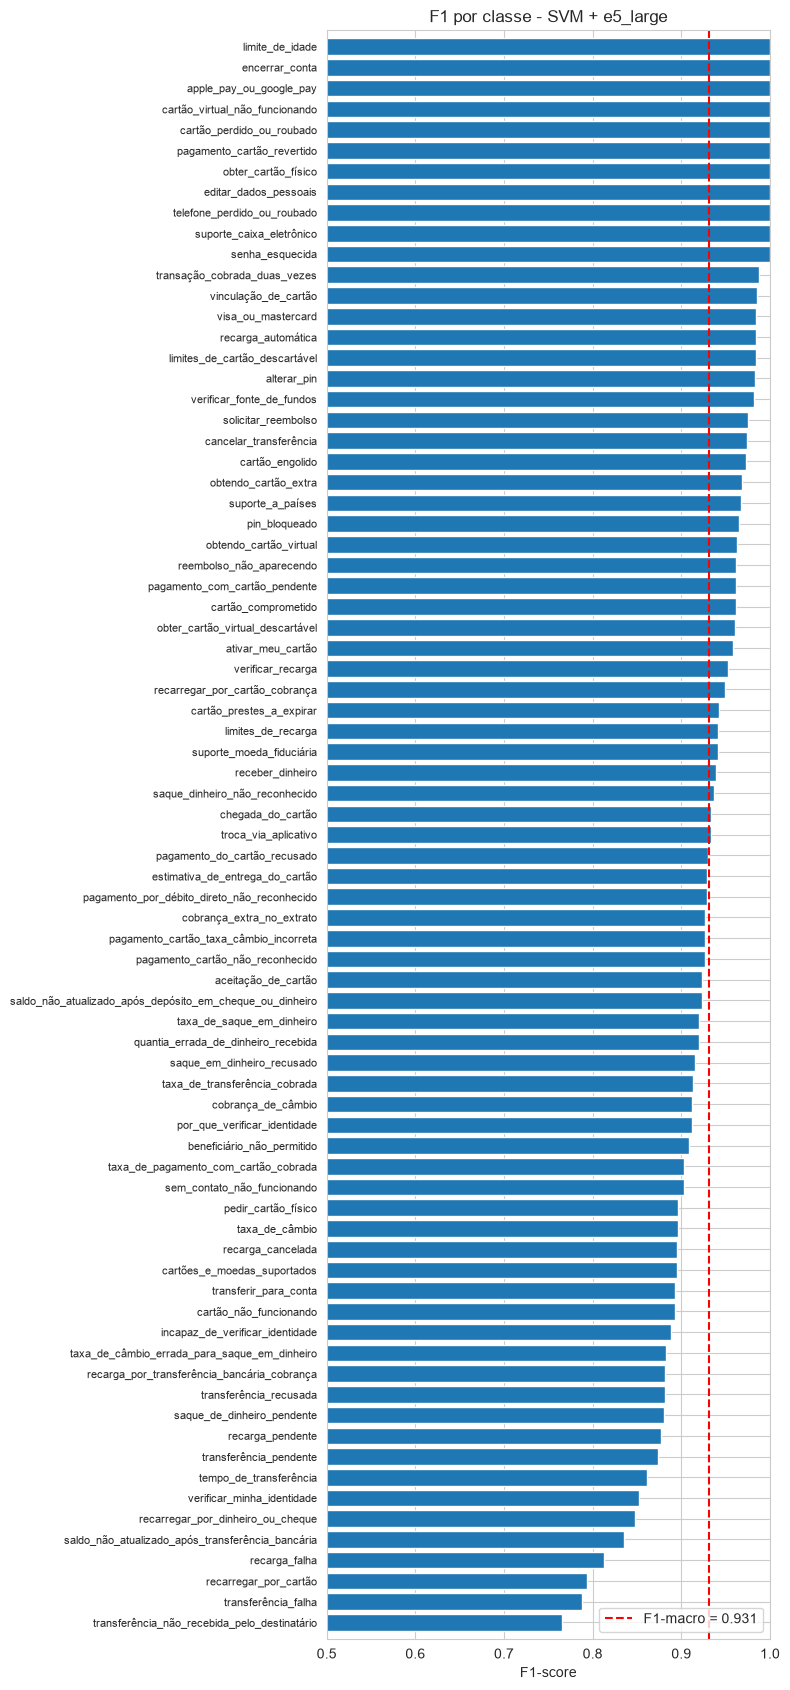

In [140]:
# F1 de cada classe, da pior para a melhor
ordem = por_classe.sort_values('f1-score')

fig, ax = plt.subplots(figsize=(8, 17))
ax.barh(ordem.index, ordem['f1-score'], color='tab:blue')
ax.axvline(por_classe['f1-score'].mean(), color='red', linestyle='--', label=f"F1-macro = {por_classe['f1-score'].mean():.3f}")
ax.set_xlim(0.5, 1.0)
ax.set_xlabel('F1-score')
ax.set_title(f'F1 por classe - {PRINCIPAL}')
ax.tick_params(axis='y', labelsize=8)
ax.margins(y=0.005)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

#### 2.2 Piores e melhores classes
Separo as 10 piores e as 10 melhores classes pelo F1. Nas piores, comparar precision e recall mostra o tipo de erro:

- **recall baixo:** o modelo deixa passar frases da classe, classificando-as como outra;
- **precision baixa:** o modelo atribui à classe frases que são de outras.

In [141]:
colunas = ['precision', 'recall', 'f1-score', 'especificidade', 'frases_teste']
print('10 piores classes')
display(ordem[colunas].head(10).round(3))
print('10 melhores classes')
display(ordem[colunas].tail(10).iloc[::-1].round(3))

10 piores classes


,precision,recall,f1-score,especificidade,frases_teste
transferência_não_recebida_pelo_destinatário,0.775,0.756,0.765,0.996,41
transferência_falha,0.765,0.812,0.788,0.997,32
recarregar_por_cartão,0.742,0.852,0.793,0.997,27
recarga_falha,0.867,0.765,0.812,0.998,34
saldo_não_atualizado_após_transferência_bancária,0.868,0.805,0.835,0.998,41
recarregar_por_dinheiro_ou_cheque,0.862,0.833,0.847,0.998,30
verificar_minha_identidade,0.765,0.963,0.852,0.997,27
tempo_de_transferência,0.795,0.939,0.861,0.997,33
transferência_pendente,0.838,0.912,0.873,0.998,34
recarga_pendente,0.865,0.889,0.877,0.998,36


10 melhores classes


,precision,recall,f1-score,especificidade,frases_teste
limite_de_idade,1.0,1.0,1.0,1.0,27
encerrar_conta,1.0,1.0,1.0,1.0,28
apple_pay_ou_google_pay,1.0,1.0,1.0,1.0,32
cartão_virtual_não_funcionando,1.0,1.0,1.0,1.0,14
cartão_perdido_ou_roubado,1.0,1.0,1.0,1.0,24
pagamento_cartão_revertido,1.0,1.0,1.0,1.0,37
obter_cartão_físico,1.0,1.0,1.0,1.0,27
editar_dados_pessoais,1.0,1.0,1.0,1.0,32
telefone_perdido_ou_roubado,1.0,1.0,1.0,1.0,32
suporte_caixa_eletrônico,1.0,1.0,1.0,1.0,24


In [142]:
# Quantidade de classes em cada faixa de F1
faixas = pd.cut(por_classe['f1-score'], bins=[0, 0.8, 0.9, 0.95, 1.0], labels=['< 0,80', '0,80 a 0,90', '0,90 a 0,95', '≥ 0,95'], right=False)
faixas = faixas.value_counts().sort_index()
faixas.index = faixas.index.astype(str)
print(faixas.to_string())
print('\nClasses com F1 = 1:', (por_classe['f1-score'] == 1).sum())

f1-score
< 0,80          3
0,80 a 0,90    18
0,90 a 0,95    25
≥ 0,95         20

Classes com F1 = 1: 11


**Resultado**

- O F1 varia bastante entre as classes, de 0,765 a 1. Das 77 classes, 11 não têm nenhum erro (F1 = 1), 45 ficam com F1 de 0,90 ou mais e só 3 ficam abaixo de 0,80.
- As piores classes são quase todas de dois temas: **transferências** (`transferência_não_recebida_pelo_destinatário`, `transferência_falha`, `saldo_não_atualizado_após_transferência_bancária`, `tempo_de_transferência`, `transferência_pendente`) e **recarga** (`recarregar_por_cartão`, `recarga_falha`, `recarregar_por_dinheiro_ou_cheque`, `recarga_pendente`). São temas com várias classes parecidas entre si. Por isso, analisarei essas categorias mais a fundo adiante.
- As melhores classes têm um assunto que nenhuma outra classe tem, como `limite_de_idade`, `encerrar_conta` e `apple_pay_ou_google_pay`.
- Como esperado, o tipo de erro muda de uma classe para outra. Por exemplo: `verificar_minha_identidade` tem recall de 0,963 e precision de 0,765, ou seja, quase não perde frases suas, mas recebe frases das outras classes de identidade. Por outro lado, `recarga_falha` tem precision de 0,867 e recall de 0,765, ou seja, o modelo deixa passar frases dela para outras classes.
- A especificidade fica entre 0,996 e 1 em todas as classes, inclusive nas piores. Portanto, ela não separa as classes boas das ruins.

### 3. Desbalanceamento
Como visto na análise exploratória, as classes têm de 71 a 225 frases (razão de 3,2 entre a maior e a menor), e a divisão estratificada mantém essas proporções no treino e no teste.

Se o desbalanceamento prejudicasse o modelo, as classes com menos frases no treino teriam F1 menor. Verifico isso com um gráfico de dispersão e a correlação entre as duas variáveis.

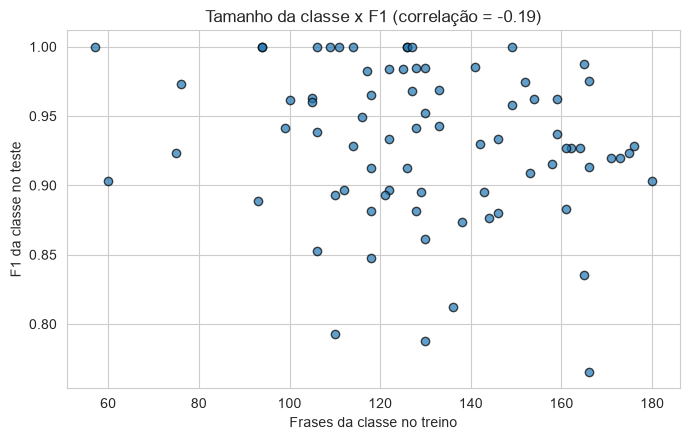

F1 médio das classes com menos de 128 frases: 0.9439
F1 médio das classes com 128 frases ou mais: 0.9185


In [143]:
correlacao = por_classe['frases_treino'].corr(por_classe['f1-score'])

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(por_classe['frases_treino'], por_classe['f1-score'], alpha=0.7, edgecolor='k')
ax.set_xlabel('Frases da classe no treino')
ax.set_ylabel('F1 da classe no teste')
ax.set_title(f'Tamanho da classe x F1 (correlação = {correlacao:.2f})')
plt.tight_layout()
plt.show()

# F1 médio das classes menores e maiores (divididas pela mediana do tamanho)
mediana = por_classe['frases_treino'].median()
print(f"F1 médio das classes com menos de {mediana:.0f} frases: {por_classe.loc[por_classe['frases_treino'] < mediana, 'f1-score'].mean():.4f}")
print(f"F1 médio das classes com {mediana:.0f} frases ou mais: {por_classe.loc[por_classe['frases_treino'] >= mediana, 'f1-score'].mean():.4f}")

**Resultado**

- Não há relação entre o tamanho da classe e o F1. A correlação é fraca e negativa (−0,19). As classes com menos frases no treino têm F1 médio maior (0,944) que as maiores (0,919). Provavelmente esse é o motivo de o balanceamento de classes (`class_weight='balanced'`) não ter ajudado os modelos.
- As classes mais tiveram maior dificuldade para classificar não foram as pequenas, mas as que têm outras classes parecidas. Várias das piores classes têm mais frases que a média de 130, como `transferência_não_recebida_pelo_destinatário` (166 frases, F1 de 0,765) e `saldo_não_atualizado_após_transferência_bancária` (165 frases, F1 de 0,835).

### 4. Análise da matriz de confusão

#### 4.1 Matriz de confusão

- Cada **linha** é a classe real e cada **coluna** é a classe prevista. A célula conta quantas frases da classe da linha o modelo classificou como a classe da coluna.
- Muitas células coloridas na linha indicam **recall** baixo.
- Muitas células coloridas na coluna indicam **precision** baixa.

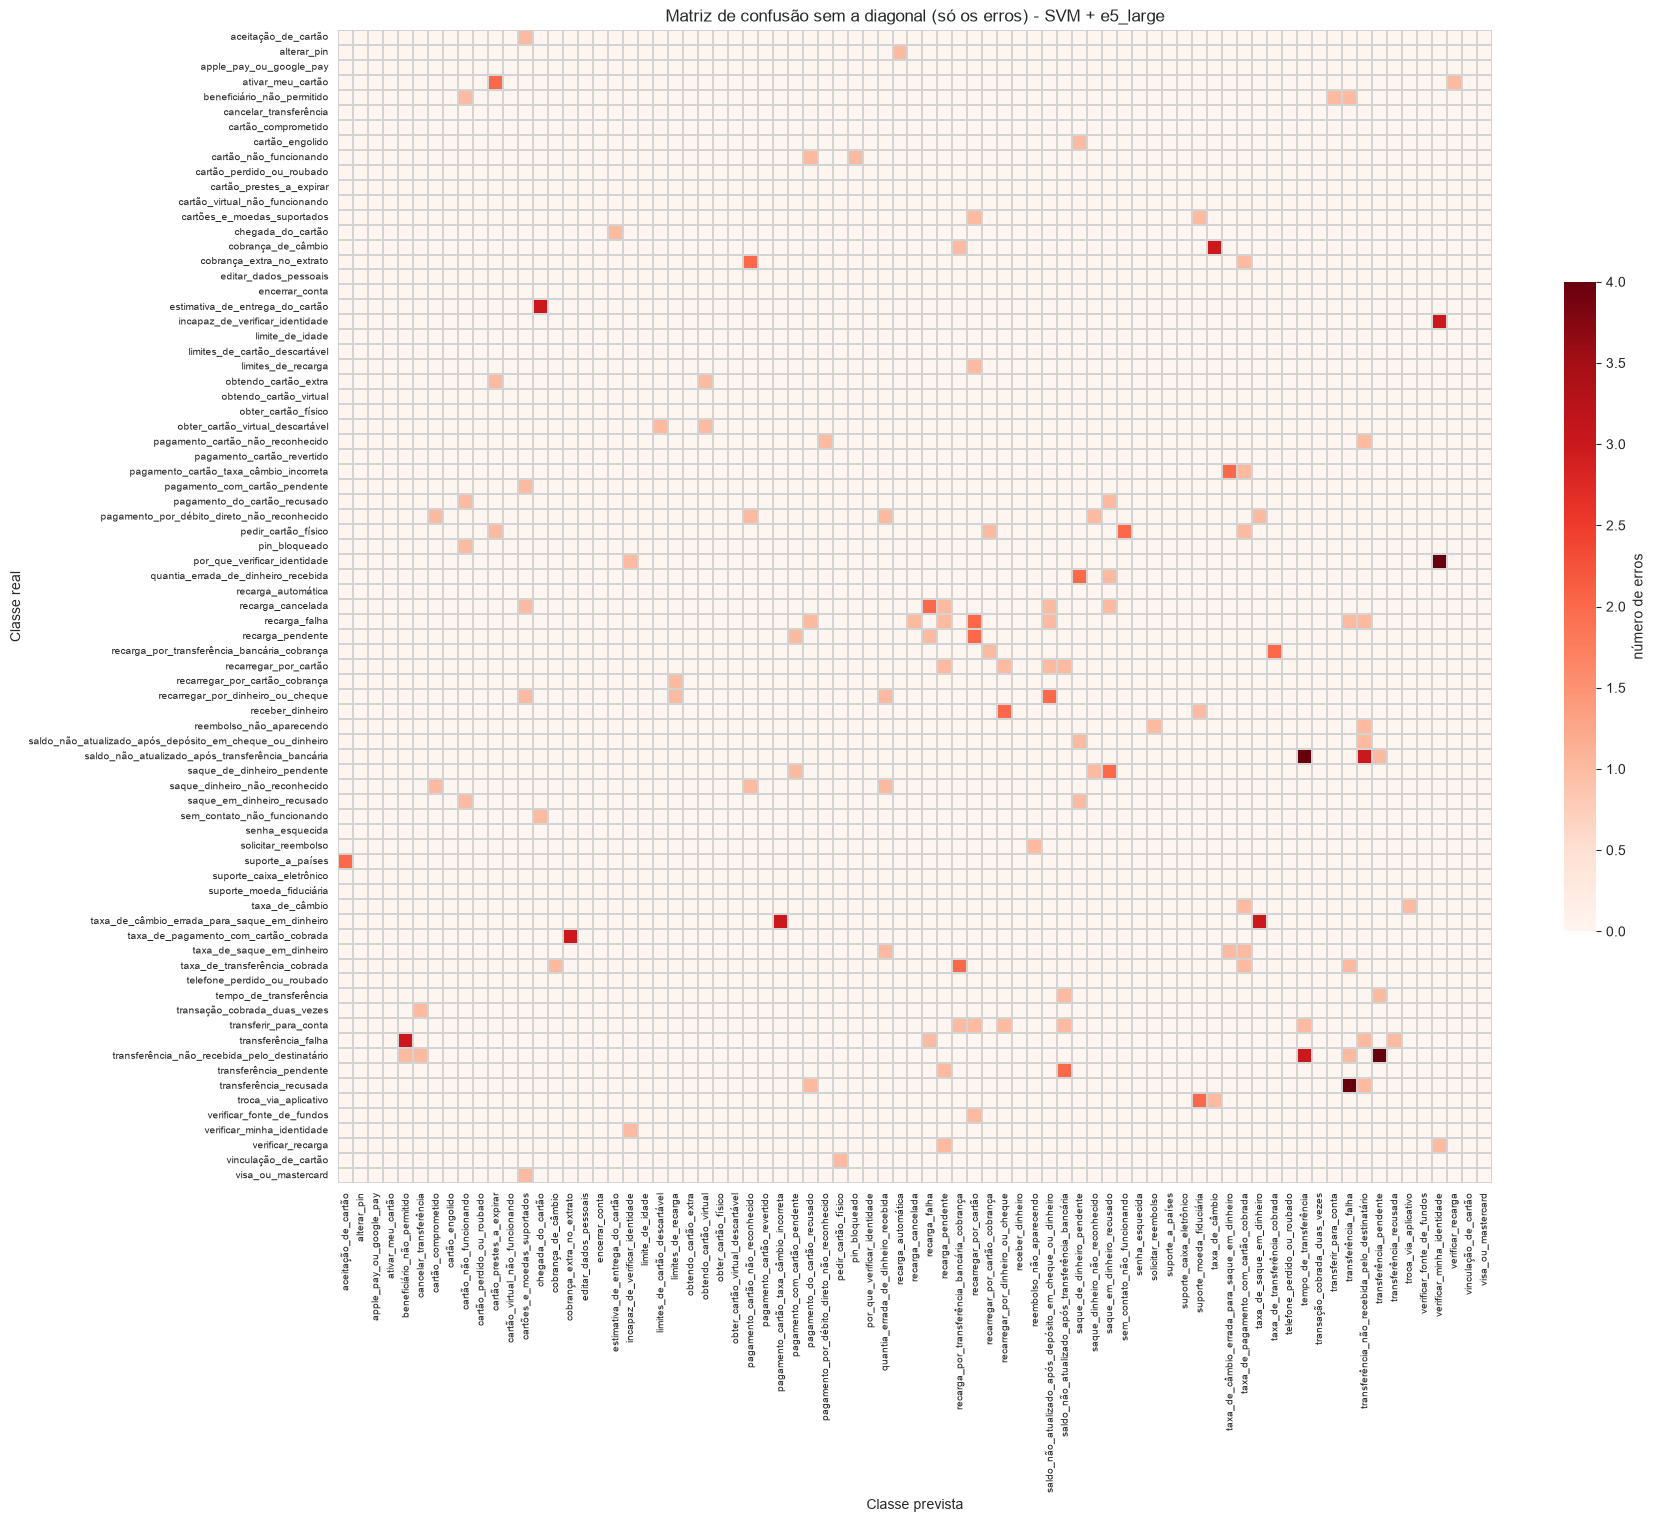

In [144]:
cm = confusion_matrix(y_test, previsto, labels=CLASSES)
erros = cm.copy()
np.fill_diagonal(erros, 0)

fig, ax = plt.subplots(figsize=(18, 16))
sns.heatmap(erros, cmap='Reds', xticklabels=CLASSES, yticklabels=CLASSES, square=True,
            linewidths=0.2, linecolor='lightgray', cbar_kws={'label': 'número de erros', 'shrink': 0.5}, ax=ax)
ax.set_xlabel('Classe prevista')
ax.set_ylabel('Classe real')
ax.set_title(f'Matriz de confusão sem a diagonal (só os erros) - {PRINCIPAL}')
ax.tick_params(labelsize=7)
plt.tight_layout()
plt.show()

#### 4.2 Como os erros se distribuem
Verifico se os erros estão espalhados pela matriz ou concentrados em poucas células (pares real → previsto).

In [145]:
total_erros = erros.sum()
celulas = erros[erros > 0]

print(f'Total de erros: {total_erros} de {len(y_test)} frases ({total_erros / len(y_test):.2%})')
print(f'Células com erro: {len(celulas)} de {77 * 76} possíveis ({len(celulas) / (77 * 76):.1%})')
print(f'Células com 1 só erro: {(celulas == 1).sum()}')

# fração dos erros que está nas células com mais erros
celulas_ordenadas = np.sort(celulas)[::-1]
for n in [10, 20]:
    print(f'As {n} células com mais erros concentram {celulas_ordenadas[:n].sum() / total_erros:.1%} dos erros')

Total de erros: 179 de 2506 frases (7.14%)
Células com erro: 133 de 5852 possíveis (2.3%)
Células com 1 só erro: 104
As 10 células com mais erros concentram 19.0% dos erros
As 20 células com mais erros concentram 31.8% dos erros


In [146]:
# Classes que mais perdem frases (falsos negativos) e que mais recebem frases de outras (falsos positivos)
fn_fp = pd.DataFrame({
    'perde (FN)': erros.sum(axis=1),
    'recebe (FP)': erros.sum(axis=0),
}, index=CLASSES)

print('Classes que mais perdem frases para outras')
display(fn_fp.sort_values('perde (FN)', ascending=False).head(8))
print('Classes que mais recebem frases de outras')
display(fn_fp.sort_values('recebe (FP)', ascending=False).head(8))

Classes que mais perdem frases para outras


,perde (FN),recebe (FP)
transferência_não_recebida_pelo_destinatário,10,9
recarga_falha,8,4
saldo_não_atualizado_após_transferência_bancária,8,5
recarga_cancelada,6,1
taxa_de_câmbio_errada_para_saque_em_dinheiro,6,3
transferência_falha,6,8
transferência_recusada,6,1
pedir_cartão_físico,5,1


Classes que mais recebem frases de outras


,perde (FN),recebe (FP)
transferência_não_recebida_pelo_destinatário,10,9
tempo_de_transferência,2,8
verificar_minha_identidade,1,8
recarregar_por_cartão,4,8
transferência_falha,6,8
taxa_de_pagamento_com_cartão_cobrada,3,6
transferência_pendente,3,6
recarga_pendente,4,5


### 5. Análise de classes parecidas

#### 5.1 Pares de classes mais confundidos
Na matriz de confusão, cada célula possui uma direção (real → previsto). Então, na tabela abaixo somo os dois sentidos (erros de A previsto como B + erros de B previsto como A). Assim fica o total de confusões entre cada par de classes.

In [147]:
confusoes = erros + erros.T  # matriz simétrica: confusões nos dois sentidos

linhas = []
for i in range(len(CLASSES)):
    for j in range(i + 1, len(CLASSES)):
        if confusoes[i, j] > 0:
            linhas.append({
                'classe_a': CLASSES[i],
                'classe_b': CLASSES[j],
                'a -> b': erros[i, j],
                'b -> a': erros[j, i],
                'total': confusoes[i, j],
            })

pares_confundidos = pd.DataFrame(linhas).sort_values('total', ascending=False).reset_index(drop=True)
print(f'Pares de classes com pelo menos uma confusão: {len(pares_confundidos)} de {77 * 76 // 2}')
print(f'Os 15 pares mais confundidos somam {pares_confundidos["total"].head(15).sum() / total_erros:.1%} dos erros')
pares_confundidos.head(15)

Pares de classes com pelo menos uma confusão: 112 de 2926
Os 15 pares mais confundidos somam 33.0% dos erros


,classe_a,classe_b,a -> b,b -> a,total
0,pagamento_cartão_taxa_câmbio_incorreta,taxa_de_câmbio_errada_para_saque_em_dinheiro,2,3,5
1,transferência_falha,transferência_recusada,1,4,5
2,saldo_não_atualizado_após_transferência_bancária,tempo_de_transferência,4,1,5
3,beneficiário_não_permitido,transferência_falha,1,3,4
4,chegada_do_cartão,estimativa_de_entrega_do_cartão,1,3,4
5,por_que_verificar_identidade,verificar_minha_identidade,4,0,4
6,cobrança_extra_no_extrato,taxa_de_pagamento_com_cartão_cobrada,1,3,4
7,incapaz_de_verificar_identidade,verificar_minha_identidade,3,1,4
8,recarga_por_transferência_bancária_cobrança,taxa_de_transferência_cobrada,2,2,4
9,transferência_não_recebida_pelo_destinatário,transferência_pendente,4,0,4


#### 5.2 Similaridade entre as classes nos embeddings
Os embeddings colocam frases de significado parecido próximas umas das outras em um espaço vetorial. Por isso, para medir o quanto duas classes são parecidas, calculo o **centroide** de cada classe.

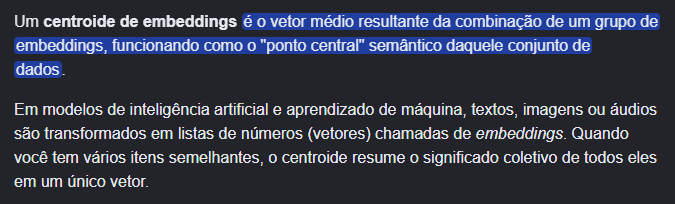

Depois, meço a **similaridade do cosseno** entre os centroides com a fórmula: \
$$\text{sim}(A, B) = \frac{c_A \cdot c_B}{\lVert c_A \rVert \, \lVert c_B \rVert}$$

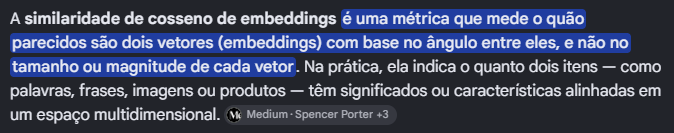

Quanto mais perto de 1, mais as frases das duas classes se parecem. A hipótese é que os pares mais confundidos são os de classes mais parecidas.
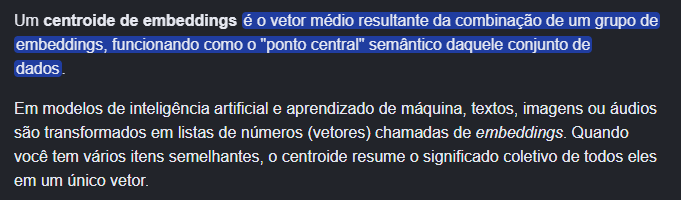

In [148]:
# Centroide de cada classe com os embeddings do treino (na ordem de CLASSES)
y_train_array = y_train.values
centroides = np.array([emb_train[y_train_array == c].mean(axis=0) for c in CLASSES])
centroides = centroides / np.linalg.norm(centroides, axis=1, keepdims=True)
similaridade = centroides @ centroides.T

# Uma linha por par de classes, com a similaridade e as confusões no teste
i, j = np.triu_indices(len(CLASSES), k=1)
todos_pares = pd.DataFrame({
    'classe_a': CLASSES[i],
    'classe_b': CLASSES[j],
    'similaridade': similaridade[i, j],
    'confusões': confusoes[i, j],
})
todos_pares['rank_similaridade'] = todos_pares['similaridade'].rank(ascending=False).astype(int)

print('10 pares de classes mais parecidos')
todos_pares.sort_values('similaridade', ascending=False).head(10).round(3)

10 pares de classes mais parecidos


,classe_a,classe_b,similaridade,confusões,rank_similaridade
1827,pagamento_cartão_taxa_câmbio_incorreta,taxa_de_câmbio_errada_para_saque_em_dinheiro,0.993,5,1
2539,saldo_não_atualizado_após_transferência_bancária,transferência_não_recebida_pelo_destinatário,0.992,3,2
2185,recarga_cancelada,recarga_falha,0.991,3,3
1723,pagamento_cartão_não_reconhecido,saque_dinheiro_não_reconhecido,0.989,1,4
1705,pagamento_cartão_não_reconhecido,pagamento_por_débito_direto_não_reconhecido,0.989,2,5
2883,transferência_falha,transferência_recusada,0.988,5,6
1752,pagamento_cartão_revertido,pagamento_do_cartão_recusado,0.987,0,7
2540,saldo_não_atualizado_após_transferência_bancária,transferência_pendente,0.987,3,8
2223,recarga_falha,recarga_pendente,0.987,2,9
360,beneficiário_não_permitido,transferência_falha,0.987,4,10


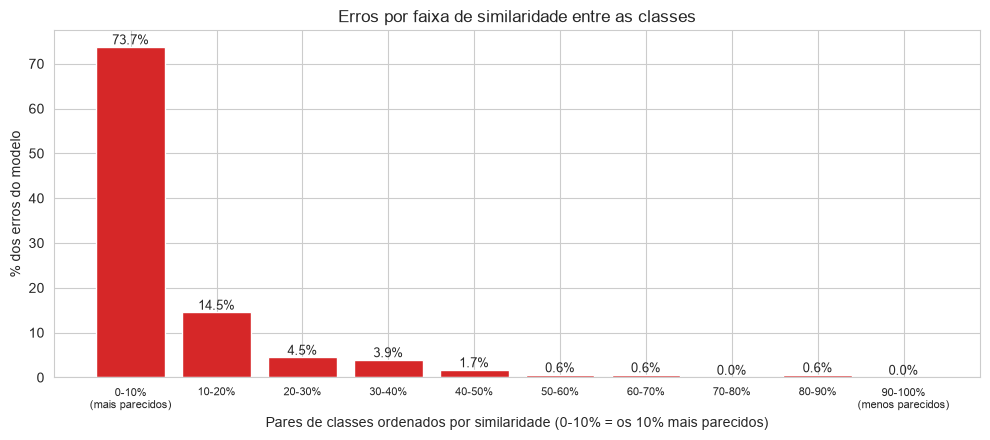

,similaridade_min,similaridade_max,erros,% dos erros
0-10%,0.966,0.993,132,73.743
10-20%,0.958,0.966,26,14.525
20-30%,0.952,0.958,8,4.469
30-40%,0.946,0.952,7,3.911
40-50%,0.940,0.946,3,1.676
50-60%,0.936,0.940,1,0.559
60-70%,0.931,0.935,1,0.559
70-80%,0.925,0.931,0,0.000
80-90%,0.919,0.925,1,0.559
90-100%,0.894,0.919,0,0.000


In [149]:
# Divide os pares em 10 faixas pela posição no ranking de similaridade (a primeira faixa tem os 10% de pares mais parecidos)
nomes_faixas = [f'{k * 10}-{k * 10 + 10}%' for k in range(10)]
nomes_faixas[0] += '\n(mais parecidos)'
nomes_faixas[-1] += '\n(menos parecidos)'
todos_pares['faixa'] = pd.qcut(todos_pares['rank_similaridade'], 10, labels=nomes_faixas)

por_faixa = todos_pares.groupby('faixa', observed=True).agg(
    similaridade_min=('similaridade', 'min'),
    similaridade_max=('similaridade', 'max'),
    erros=('confusões', 'sum'),
)
por_faixa['% dos erros'] = por_faixa['erros'] / por_faixa['erros'].sum() * 100

fig, ax = plt.subplots(figsize=(10, 4.5))
barras = ax.bar(por_faixa.index.astype(str), por_faixa['% dos erros'], color='tab:red')
ax.bar_label(barras, fmt='%.1f%%', fontsize=9)
ax.set_xlabel('Pares de classes ordenados por similaridade (0-10% = os 10% mais parecidos)')
ax.set_ylabel('% dos erros do modelo')
ax.set_title('Erros por faixa de similaridade entre as classes')
ax.tick_params(axis='x', labelsize=8)
plt.tight_layout()
plt.show()

por_faixa.index = [n.split('\n')[0] for n in por_faixa.index]
por_faixa.round(3)

**Resultado:**

**A hipótese é confirmada**. Quanto mais parecidas são duas classes, mais o modelo as confunde. Os 10% de pares mais parecidos concentram 73,7% dos erros, e os 20% mais parecidos, 88,3%. A metade menos parecida dos pares tem só 1,7% dos erros.

**Nem todo par parecido é confundido**. Por exemplo: `pagamento_cartão_revertido` e `pagamento_do_cartão_recusado` são o 7º par mais parecido e não têm nenhuma confusão. A similaridade acaba sendo um indicador de onde o modelo pode, mas não necessariamente vai, errar.

#### 5.3 Exemplos de erros
Exemplos de algumas frases dos pares mais confundidos.

In [150]:
pd.set_option('display.max_colwidth', 120)

erradas = pd.DataFrame({'frase': X_test.values, 'real': y_test.values, 'previsto': previsto})
erradas = erradas[erradas['real'] != erradas['previsto']]

for _, par in pares_confundidos.head(4).iterrows():
    exemplos = erradas[((erradas['real'] == par['classe_a']) & (erradas['previsto'] == par['classe_b'])) |
                       ((erradas['real'] == par['classe_b']) & (erradas['previsto'] == par['classe_a']))]
    print(f"{par['classe_a']}  x  {par['classe_b']}")
    display(exemplos.head(4))

pagamento_cartão_taxa_câmbio_incorreta  x  taxa_de_câmbio_errada_para_saque_em_dinheiro


,frase,real,previsto
548,Você está enganando as pessoas com a taxa de câmbio? Não pode ser tão atroz entre os bancos.,pagamento_cartão_taxa_câmbio_incorreta,taxa_de_câmbio_errada_para_saque_em_dinheiro
958,A taxa de câmbio para o caso no exterior está aplicada de forma errada.,taxa_de_câmbio_errada_para_saque_em_dinheiro,pagamento_cartão_taxa_câmbio_incorreta
1055,"Na minha última viagem, recebi a taxa de câmbio incorreta.",taxa_de_câmbio_errada_para_saque_em_dinheiro,pagamento_cartão_taxa_câmbio_incorreta
1940,Por que a taxa de câmbio é diferente do que eu esperava?,pagamento_cartão_taxa_câmbio_incorreta,taxa_de_câmbio_errada_para_saque_em_dinheiro


transferência_falha  x  transferência_recusada


,frase,real,previsto
61,Minha transferência não foi aprovada.,transferência_recusada,transferência_falha
528,"Não consigo fazer nenhuma transferência, elas não estão passando, os dados estão corretos, pois eu os verifiquei. Vo...",transferência_recusada,transferência_falha
1185,Por que todas as minhas transferências estão falhando? Eu tenho os dados certos e elas não estão sendo completadas. ...,transferência_recusada,transferência_falha
2214,O que impediu minha transferência de ser aceita?,transferência_falha,transferência_recusada


saldo_não_atualizado_após_transferência_bancária  x  tempo_de_transferência


,frase,real,previsto
256,Quanto tempo leva uma transferência do Reino Unido?,saldo_não_atualizado_após_transferência_bancária,tempo_de_transferência
271,Quanto tempo vai levar até que eu possa acessar minha transferência?,saldo_não_atualizado_após_transferência_bancária,tempo_de_transferência
703,Por que a transferência ainda não apareceu na minha conta?,tempo_de_transferência,saldo_não_atualizado_após_transferência_bancária
1182,Onde está a transferência para a minha conta?,saldo_não_atualizado_após_transferência_bancária,tempo_de_transferência


beneficiário_não_permitido  x  transferência_falha


,frase,real,previsto
139,"Por que não posso transferir meu dinheiro para a conta de outra pessoa? Eu deveria conseguir fazer isso, certo? Por ...",transferência_falha,beneficiário_não_permitido
1704,"Erros continuam aparecendo toda vez que tento fazer essa transferência e estou com pouco tempo, você poderia me ajud...",transferência_falha,beneficiário_não_permitido
1848,"Recebi uma mensagem de falha na transferência, mas sem explicação do porquê-- o que aconteceu?",transferência_falha,beneficiário_não_permitido
1906,Há algo me impedindo de fazer transferências?,beneficiário_não_permitido,transferência_falha


Muitas das frases erradas são ambíguas. Dentre as causas possíveis, as que acho mais provável são: a tradução do inglês para o português, feita com modelos do ChatGPT, que pode ter apagado diferenças entre as classes; frases que já cabiam em mais de uma classe no original; e erros de rótulo.

- **Frase sem a informação que define a classe:** *"Na minha última viagem, recebi a taxa de câmbio incorreta."* está rotulada como `taxa_de_câmbio_errada_para_saque_em_dinheiro`, mas não fala de saque. Pode muito bem ser um pagamento com cartão, que foi o que o modelo previu (`pagamento_cartão_taxa_câmbio_incorreta`).
- **Classes com diferença pequena:** em `transferência_falha` × `transferência_recusada`, frases como *"Minha transferência não foi aprovada."* cabem nas duas. A diferença entre *failed* e *declined* já é pequena em inglês e pode ter ficado ainda menos clara na tradução. A frase *"O que impediu minha transferência de ser aceita?"* torna isso mais evidente. O rótulo real dela é `transferência_falha`, mas o modelo previu `transferência_recusada`, o que faz mais sentido pela própria frase, já que uma transferência que não foi aceita foi, por lógica, recusada. Ou seja, o rótulo diz que houve uma falha, mas o texto não deixa isso claro.
- **Rótulo duvidoso:** A frase *"Quanto tempo leva uma transferência do Reino Unido?"* está rotulada como `saldo_não_atualizado_após_transferência_bancária`, mas é uma pergunta típica de `tempo_de_transferência`, a classe que o modelo previu. Aqui o erro parece ser do rótulo, e não do modelo.

Ou seja, parte dos erros que sobram não seria resolvida com um modelo melhor. Nesses casos, a própria frase não tem informação suficiente para escolher entre as duas classes, ou o rótulo está errado.

### 6. Curva de aprendizado

Faço um estudo de como o F1-macro do modelo muda com a **quantidade de frases de treino por classe**. A pergunta que quero responder é: quantas frases rotuladas por classe o modelo precisa para chegar perto do desempenho com o treino inteiro?

Para cada quantidade testada (5, 10, 20, 30, 40, 50, 75 e 100 frases por classe):

1. sorteio essa quantidade de frases de cada classe do treino (as classes com menos frases entram com todas as que têm);
2. treino o modelo com os hiperparâmetros escolhidos no notebook 03;
3. calculo o F1-macro no teste.

O resultado depende de quais frases foram sorteadas, principalmente quando são poucas. Por isso, repito o sorteio 5 vezes e uso a média. Faço isso para o SVM + `e5_large` e para o SVM + TF-IDF.

No gráfico, as linhas tracejadas mostram o F1-macro de cada modelo treinado com o treino inteiro (em média 130 frases por classe), calculado na seção 1.

In [151]:
FRASES_POR_CLASSE = [5, 10, 20, 30, 40, 50, 75, 100]
N_SORTEIOS = 5

# Sorteia n frases de cada classe do treino (ou todas, se a classe tiver menos que n) e devolve as posições sorteadas
def sortear_por_classe(n, semente):
    rng = np.random.default_rng(semente)
    posicoes = []
    for classe in CLASSES:
        da_classe = np.where(y_train.values == classe)[0]
        posicoes.extend(rng.choice(da_classe, size=min(n, len(da_classe)), replace=False))
    return np.array(posicoes)

linhas = []
for nome in ['SVM + e5_large', 'SVM + TF-IDF']:
    busca, X_tr, X_te = MODELOS[nome]
    for n in FRASES_POR_CLASSE:
        for semente in range(N_SORTEIOS):
            posicoes = sortear_por_classe(n, semente)
            X_sorteado = X_tr.iloc[posicoes] if isinstance(X_tr, pd.Series) else X_tr[posicoes]

            modelo = clone(busca.best_estimator_)  # mesmo modelo e hiperparâmetros, ainda sem treinar
            modelo.fit(X_sorteado, y_train.values[posicoes])
            linhas.append({
                'modelo': nome,
                'frases_por_classe': n,
                'sorteio': semente,
                'f1_macro': f1_score(y_test, modelo.predict(X_te), average='macro'),
            })

resultados_curva = pd.DataFrame(linhas)

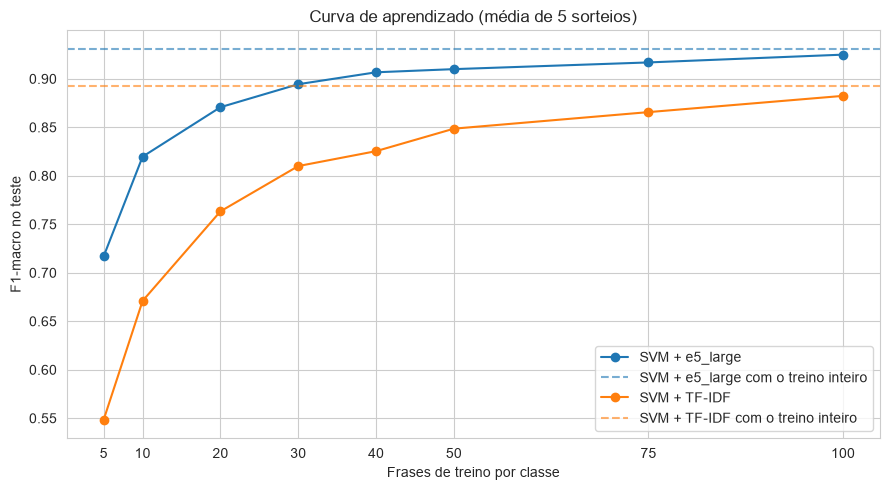

modelo,SVM + e5_large,SVM + TF-IDF
frases_por_classe,,
5,0.7171,0.5485
10,0.8197,0.6710
20,0.8707,0.7633
30,0.8944,0.8100
40,0.9067,0.8254
50,0.9099,0.8486
75,0.9169,0.8656
100,0.9249,0.8824
treino inteiro,0.9307,0.8922


In [152]:
cores = {'SVM + e5_large': 'tab:blue', 'SVM + TF-IDF': 'tab:orange'}
media_curva = resultados_curva.groupby(['frases_por_classe', 'modelo'])['f1_macro'].mean().unstack()[list(cores)]

fig, ax = plt.subplots(figsize=(9, 5))
for nome in media_curva.columns:
    ax.plot(media_curva.index, media_curva[nome], marker='o', color=cores[nome], label=nome)
    # F1-macro do modelo treinado com o treino inteiro (seção 1), como referência
    ax.axhline(tabela_metricas.loc[nome, 'f1_macro'], color=cores[nome], linestyle='--', alpha=0.6,
               label=f'{nome} com o treino inteiro')

ax.set_xticks(FRASES_POR_CLASSE)
ax.set_xlabel('Frases de treino por classe')
ax.set_ylabel('F1-macro no teste')
ax.set_title('Curva de aprendizado (média de 5 sorteios)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

# Tabela com a média de cada quantidade e o treino inteiro na última linha
tabela_curva = media_curva.copy()
tabela_curva.loc['treino inteiro'] = tabela_metricas.loc[media_curva.columns, 'f1_macro']
tabela_curva.round(4)

**Resultado**

- **Os embeddings precisam de muito menos dados.** Com 30 frases por classe, o SVM + `e5_large` chega a 0,894 de F1-macro e já passa o SVM + TF-IDF treinado com o treino inteiro (0,892).
- **Com poucas frases a diferença é enorme**: com 5 frases por classe, 0,717 dos embeddings contra 0,549 do TF-IDF. Com 10, 0,820 contra 0,671.
- **Mais dados ajudariam pouco no `e5_large`.** A curva sobe rápido até cerca de 40 frases por classe (0,907) e depois quase fica plana (de 40 frases por classe até o treino inteiro, o ganho é de 2,4 pp). Ou seja, com cerca de 3.000 frases rotuladas (40 x 77 rótulos), ele fica perto do desempenho obtido com as 10.024 do treino.
- Já o TF-IDF ainda sobe no fim da curva (+3,38 pp de 50 para 100 frases por classe), então ele depende mais da quantidade de dados rotulados.
- Na prática, isso indica que o esforço de rotulação pode ser bem menor com o `e5_large`.
- Essa curva também vai servir na comparação com as LLMs. Se uma LLM sem exemplos (*zero-shot*) chegar a 0,87 de F1-macro, por exemplo, ela equivale ao `e5_large` treinado com só 20 frases por classe.

### 7. Projeção: PCA

Cada frase é representada pelo `e5_large` como um vetor de **1024 números** (dimensões). Métodos de projeção representam esses dados com menos dimensões. Uso o **PCA (Análise de Componentes Principais)**.

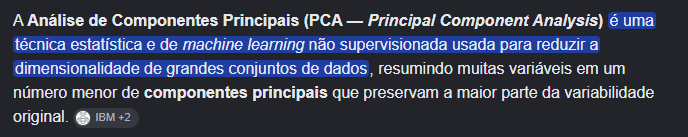

O PCA encontra novas direções no espaço, os **componentes principais**. Cada componente é uma combinação linear das 1024 dimensões originais, e eles são ordenados pela quantidade de variância dos dados que explicam: o 1º componente é a direção em que os dados mais variam, o 2º é a próxima direção (perpendicular à 1ª), e assim por diante. Se poucos componentes explicam quase toda a variância, dá para descartar o resto e trabalhar com menos dimensões, perdendo pouca informação.

Uso o PCA para testar se reduzir a dimensão dos embeddings melhora o modelo.

#### 7.1 Variância explicada pelo PCA
Ajusto o PCA nos embeddings do treino e calculo a **variância explicada acumulada**: a fração da variância total dos dados que os $k$ primeiros componentes explicam juntos.

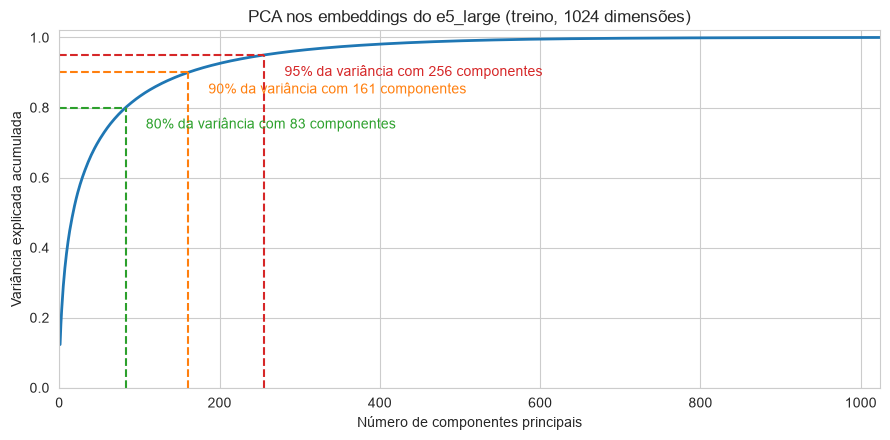

Os 2 primeiros componentes explicam só 18.1% da variância


In [153]:
from sklearn.decomposition import PCA

pca = PCA(random_state=RANDOM_STATE).fit(emb_train)
variancia_acumulada = np.cumsum(pca.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(np.arange(1, len(variancia_acumulada) + 1), variancia_acumulada, color='tab:blue', linewidth=2)
for alvo, cor in [(0.8, 'tab:green'), (0.9, 'tab:orange'), (0.95, 'tab:red')]:
    k = np.searchsorted(variancia_acumulada, alvo) + 1  # menor número de componentes que atinge o alvo
    ax.plot([k, k], [0, alvo], color=cor, linestyle='--')
    ax.plot([0, k], [alvo, alvo], color=cor, linestyle='--')
    ax.annotate(f'{alvo:.0%} da variância com {k} componentes', (k, alvo), xytext=(k + 25, alvo - 0.06), color=cor, fontsize=10)
ax.set_xlim(0, emb_train.shape[1])
ax.set_ylim(0, 1.02)
ax.set_xlabel('Número de componentes principais')
ax.set_ylabel('Variância explicada acumulada')
ax.set_title('PCA nos embeddings do e5_large (treino, 1024 dimensões)')
plt.tight_layout()
plt.show()

print(f'Os 2 primeiros componentes explicam só {variancia_acumulada[1]:.1%} da variância')

#### 7.2 Reduzir a dimensão melhora o modelo?
Treino o SVM com os mesmos hiperparâmetros escolhidos no notebook 03, mas usando como entrada só os $k$ primeiros componentes do PCA, para vários valores de $k$. A última configuração usa as 1024 dimensões originais, sem PCA.

Para não usar o teste na escolha de $k$, avalio com a mesma **validação cruzada de 5 folds no treino** da modelagem.

Além do F1-macro, registro o tempo médio de treino em cada fold, já que uma das vantagens esperadas de reduzir a dimensão é deixar o modelo mais rápido.

In [154]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline

cv_estratificado = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)  # mesmos folds do notebook 03
svm_escolhido = MODELOS[PRINCIPAL][0].best_estimator_.named_steps['clf']  # SVM com os hiperparâmetros escolhidos

COMPONENTES = [2, 10, 25, 50, 100, 200, 300, 500, None]  # None = sem PCA (1024 dimensões)
linhas = []
for k in COMPONENTES:
    etapa_pca = PCA(n_components=k, random_state=RANDOM_STATE) if k else 'passthrough'
    pipeline = Pipeline([('pca', etapa_pca), ('clf', clone(svm_escolhido))])
    resultado = cross_validate(pipeline, emb_train, y_train, cv=cv_estratificado, scoring='f1_macro', n_jobs=-1)
    linhas.append({
        'componentes': k if k else emb_train.shape[1],
        'variância_explicada': variancia_acumulada[k - 1] if k else 1.0,
        'f1_macro_cv': resultado['test_score'].mean(),
        'tempo_treino_s': resultado['fit_time'].mean(),
    })

resultados_pca = pd.DataFrame(linhas)
resultados_pca.round(4)

,componentes,variância_explicada,f1_macro_cv,tempo_treino_s
0,2,0.1806,0.0985,2.1897
1,10,0.4010,0.7924,1.5229
2,25,0.5730,0.8870,1.8657
3,50,0.7077,0.9104,2.3952
4,100,0.8313,0.9209,3.4148
5,200,0.9259,0.9246,5.0013
6,300,0.9631,0.9262,6.7700
7,500,0.9905,0.9267,9.3047
8,1024,1.0000,0.9286,6.6073


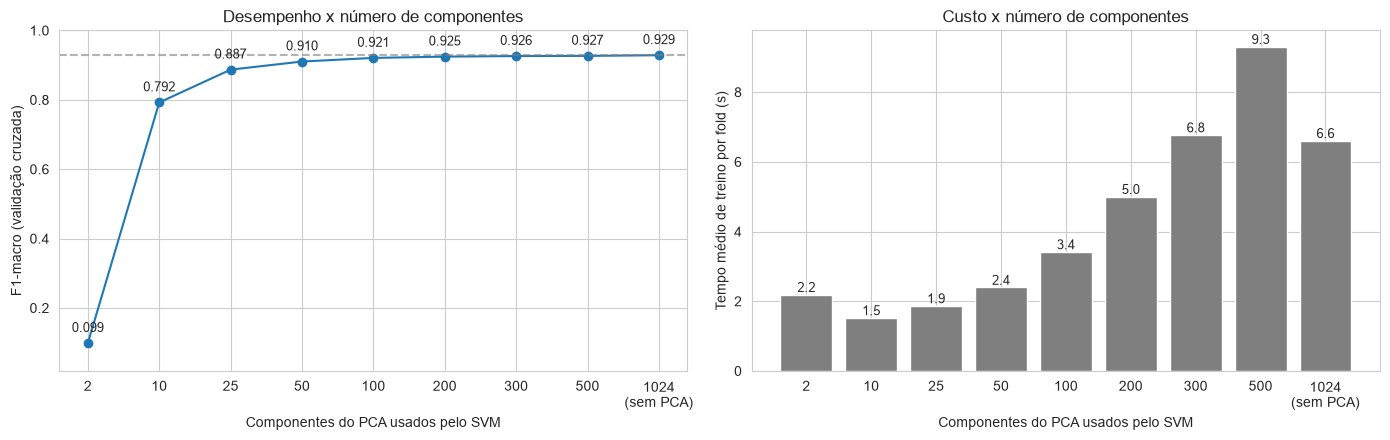

In [155]:
rotulos_k = [str(k) for k in resultados_pca['componentes'][:-1]] + ['1024\n(sem PCA)']
posicoes = np.arange(len(resultados_pca))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

ax = axes[0]
ax.plot(posicoes, resultados_pca['f1_macro_cv'], marker='o', color='tab:blue')
for x, f1 in zip(posicoes, resultados_pca['f1_macro_cv']):
    ax.annotate(f'{f1:.3f}', (x, f1), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=9)
ax.axhline(resultados_pca['f1_macro_cv'].iloc[-1], color='gray', linestyle='--', alpha=0.6)
ax.set_xticks(posicoes, rotulos_k)
ax.set_ylim(resultados_pca['f1_macro_cv'].min() - 0.08, 1.0)
ax.set_xlabel('Componentes do PCA usados pelo SVM')
ax.set_ylabel('F1-macro (validação cruzada)')
ax.set_title('Desempenho x número de componentes')

ax = axes[1]
barras = ax.bar(posicoes, resultados_pca['tempo_treino_s'], color='tab:gray')
ax.bar_label(barras, fmt='%.1f', fontsize=9)
ax.set_xticks(posicoes, rotulos_k)
ax.set_xlabel('Componentes do PCA usados pelo SVM')
ax.set_ylabel('Tempo médio de treino por fold (s)')
ax.set_title('Custo x número de componentes')

plt.tight_layout()
plt.show()

**Resultado**

- **A maior parte da variância está em poucos componentes.** A curva sobe rápido e depois quase fica plana: 83 componentes já explicam 80% da variância, 161 explicam 90% e 256 explicam 95%. Ou seja, boa parte das 1024 dimensões é redundante.
- **Reduzir a dimensão não melhorou o modelo.** O F1-macro cresce com o número de componentes, e o melhor resultado continua sendo o das 1024 dimensões originais (0,9286). A perda, porém, é pequena a partir de cerca de 100 componentes: com 100 (83% da variância), o F1-macro é 0,921 (−0,8 pp); com 200 (93%), é 0,925 (−0,4 pp).
- Com poucos componentes, o modelo perde informação demais: com 10 componentes, o F1-macro cai para 0,792; com 2, para 0,099.
- **A vantagem do PCA é o custo.** Com 100 componentes, o treino fica cerca de 2 vezes mais rápido (3,1 s contra 6,0 s por fold nesta execução). O tempo inclui o ajuste do PCA e varia um pouco de uma execução para outra (por isso 500 componentes aparecem mais lentos que 1024). Com 2 componentes o treino também fica lento, provavelmente porque, com as classes todas misturadas, o SVM precisa de muitos vetores de suporte.
- Como o SVM já é rápido com esse volume de dados, mantenho o modelo sem PCA. Com muito mais dados, usar cerca de 200 componentes seria uma boa troca entre desempenho e custo.

### 8. Conclusões

- **O SVM + `e5_large`** é o melhor dos três modelos em todas as métricas (F1-macro de 0,9307 no teste), mas com pouca diferença para a Regressão Logística com o mesmo embedding. O ganho grande vem da representação: +3,85 pp sobre o TF-IDF.
- O desbalanceamento entre as classes (razão de 3,2) não atrapalha o modelo. As médias macro e weighted ficam quase iguais, o tamanho da classe não tem relação com o F1 e, como visto na modelagem, o balanceamento de classes (`class_weight='balanced'`) praticamente não muda o resultado.
- A especificidade fica perto de 1 em todas as classes e não ajuda a avaliar o modelo. Precision, recall e F1 são as métricas que mostram os erros.
- Os erros são poucos e se concentram em pares de classes parecidas, principalmente dos temas de transferências, recarga, câmbio e verificação de identidade. A similaridade cosseno entre os centroides dos embeddings mostra bem onde o modelo vai errar.
- Parte dos erros vem de frases ambíguas ou com rótulo "errado", que nenhum modelo resolveria.
- A curva de aprendizado mostra que o `e5_large` passa o TF-IDF treinado com o treino inteiro usando só 30 frases por classe, e que, a partir de cerca de 40 frases por classe, rotular mais frases traria pouco ganho. Ela será a referência na comparação com as LLMs.
- **Projeção:** reduzir a dimensão com o PCA não melhorou o modelo (o melhor F1-macro na validação cruzada continua com as 1024 dimensões), mas com 200 componentes a perda é de só 0,4 pp, com treino mais rápido.

### 9. Sumário da parte clássica

**Pergunta:** é possível classificar automaticamente as mensagens de clientes de um banco nas 77 categorias de atendimento, usando apenas o texto?

**Dados e preparação (notebook 01):** dataset Banking77 traduzido para o português (13.085 mensagens). Removi colunas sem utilidade, linhas vazias, linhas que não eram mensagens de clientes, anotações do revisor, duplicatas e frases com mais de um rótulo, e corrigi o erro sistemático de tradução de *top up* ("abastecer" no lugar de "recarregar"). Restaram 12.530 mensagens.

**Análise exploratória (notebook 02):** desbalanceamento moderado (71 a 225 frases por classe), frases curtas (mediana de 9 palavras) e classes do mesmo tema compartilhando as palavras mais frequentes e distintivas. Por isso, usei divisão estratificada, F1-macro como métrica principal e mantive as negações fora da lista de stopwords.

**Modelagem (notebook 03):** é um problema de **classificação supervisionada multiclasse**. Comparei TF-IDF (com ajuste de n-gramas, stopwords, `min_df` e `sublinear_tf`) e embeddings de três modelos de linguagem, com Regressão Logística, SVM, Random Forest e XGBoost. Os hiperparâmetros foram escolhidos com validação cruzada estratificada de 5 folds no treino, e o teste foi usado uma única vez.

**Resultado final:** o melhor modelo é o **SVM (kernel RBF) sobre os embeddings do `e5_large`**, com **0,9307 de F1-macro** e **92,86% de acurácia** no teste (+6,53 pp de F1-macro sobre o baseline).

| Hipótese | Resultado |
|---|---|
| **H1:** é possível classificar as 77 intenções com F1-macro acima de 0,90 | **Confirmada:** 0,9307 no teste (e acima de 0,90 com os 6 modelos de embeddings) |
| **H2:** a representação do texto pesa mais que o classificador | **Confirmada:** todos os modelos com embeddings superam todos com TF-IDF; com a mesma representação, SVM e Regressão Logística ficam a menos de 0,5 pp |
| Bigramas e trigramas ajudam a separar rótulos parecidos | **Refutada:** unigramas foram melhores |
| Remover stopwords (mantendo as negações) ajuda | **Refutada:** piorou os modelos em 1,3 a 1,5 pp |
| O desbalanceamento prejudica as classes menores | **Refutada:** o tamanho da classe não tem relação com o F1 |
| Os erros se concentram nas classes mais parecidas | **Confirmada:** os 10% de pares mais parecidos concentram 73,7% dos erros |
| Reduzir a dimensão com PCA melhora o modelo | **Refutada:** o PCA não melhora, mas mantém quase o mesmo F1-macro com 200 das 1024 dimensões |

**Principais resultados:**
- Os erros são poucos (7,1% das frases) e se concentram em pares de classes parecidas (transferências, recarga, câmbio e verificação de identidade). Parte deles vem de frases ambíguas ou com rótulo duvidoso.
- Com só 30 frases rotuladas por classe, o SVM + `e5_large` já supera o SVM + TF-IDF treinado com todos os dados.

**O que pode ser feito para melhorar:**
- revisar os rótulos das frases ambíguas ou duvidosas encontradas na análise de erros;
- tratar juntas as classes que quase não se distinguem ou, na prática, pedir uma confirmação ao cliente quando o modelo ficar em dúvida entre duas classes;
- rotular mais exemplos só para os pares confundidos, já que mais dados em geral trariam pouco ganho;
- fazer o ajuste fino (*fine-tuning*) de um modelo de linguagem na tarefa, em vez de usar os embeddings prontos.

**Próxima etapa: comparação com LLMs**

A próxima etapa do projeto é comparar o modelo vencedor com modelos de linguagem grandes (LLMs), usados por API sem nenhum treino. Nesse caso, a LLM recebe a mensagem e a lista das 77 categorias e responde qual é a categoria (*zero-shot*), ou recebe também alguns exemplos de cada categoria (*few-shot*). O plano é:

- classificar as frases do teste com LLMs, nas versões *zero-shot* e *few-shot*;
- comparar com o SVM + `e5_large` usando as mesmas métricas (F1-macro e acurácia), além do custo e do tempo de resposta por mensagem;
- verificar se as LLMs erram nos mesmos pares de classes parecidas que o SVM.

A pergunta é se uma LLM, que não precisa de frases rotuladas para ser treinada, consegue chegar perto do SVM, que é muito mais barato e rápido de usar depois de treinado.